In [ ]:
import numpy as np, json, pandas as pd
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier

d = fetch_olivetti_faces()
X, y = d.data, d.target

s = np.load("split.npz")
tr, va, te = s["tr"], s["va"], s["te"]
Xtr, ytr = X[tr], y[tr]
Xva, yva = X[va], y[va]
Xte, yte = X[te], y[te]

def mask(Xs):
    Xm = Xs.copy().reshape(-1, 64, 64)
    Xm[:, 24:40, 24:40] = 0
    return Xm.reshape(len(Xs), -1)

Xte_m = mask(Xte)
print(Xtr.shape, Xva.shape, Xte.shape)   # expect (240,4096) (80,4096) (80,4096)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(240, 4096) (80, 4096) (80, 4096)


In [ ]:
rows = []
for depth in [2, 4, 8, 16, None]:
    for leaf in [1, 2, 4]:
        clf = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                     random_state=0).fit(Xtr, ytr)
        t = clf.tree_
        is_leaf = t.children_left == -1
        leaf_sizes = t.n_node_samples[is_leaf]
        rows.append(dict(
            depth=str(depth), min_leaf=leaf,
            train=clf.score(Xtr, ytr),
            val=clf.score(Xva, yva),
            test=clf.score(Xte, yte),
            n_leaves=int(is_leaf.sum()),
            mean_per_leaf=len(Xtr) / is_leaf.sum(),
            frac_singleton=(leaf_sizes == 1).mean()))

df = pd.DataFrame(rows)
print(df.round(3).to_string())

# choose using VALIDATION only; tie-break = fewest leaves (simplest tree)
best = df.sort_values(["val", "n_leaves"], ascending=[False, True]).iloc[0]
print("\nFROZEN SETTING:\n", best)

df.to_csv("q1a_results.csv", index=False)
json.dump({"depth": None if best.depth == "None" else int(best.depth),
           "min_samples_leaf": int(best.min_leaf)}, open("frozen_tree.json", "w"))

   depth  min_leaf  train    val   test  n_leaves  mean_per_leaf  frac_singleton
0      2         1  0.075  0.062  0.062         3         80.000           0.000
1      2         2  0.075  0.062  0.062         3         80.000           0.000
2      2         4  0.075  0.062  0.062         3         80.000           0.000
3      4         1  0.125  0.100  0.112         5         48.000           0.000
4      4         2  0.125  0.100  0.112         5         48.000           0.000
5      4         4  0.125  0.100  0.112         5         48.000           0.000
6      8         1  0.225  0.188  0.188         9         26.667           0.000
7      8         2  0.225  0.188  0.188         9         26.667           0.000
8      8         4  0.225  0.188  0.188         9         26.667           0.000
9     16         1  0.425  0.300  0.338        17         14.118           0.000
10    16         2  0.425  0.300  0.338        17         14.118           0.000
11    16         4  0.425  0

In [ ]:
import pickle

ROLL = "M26ECM505"          # <- same roll number as in split.npz
SEED = int("".join(c for c in ROLL if c.isdigit()))
rng = np.random.default_rng(SEED)

frozen = json.load(open("frozen_tree.json"))
params = dict(max_depth=frozen["depth"], min_samples_leaf=frozen["min_samples_leaf"])
K, n, BMAX = 40, len(Xtr), 200

trees, bags = [], []
for b in range(BMAX):
    idx = rng.integers(0, n, n)                      # bootstrap: n draws with replacement
    t = DecisionTreeClassifier(**params, random_state=int(rng.integers(1_000_000_000)))
    t.fit(Xtr[idx], ytr[idx])
    trees.append(t); bags.append(idx)

pickle.dump((trees, bags), open("bag200.pkl", "wb"))

In [ ]:
# every tree's prediction on every set, computed once
Y = {"train": ytr, "val": yva, "test": yte}
S = {"train": Xtr, "val": Xva, "test": Xte}
P = {k: np.array([t.predict(S[k]) for t in trees]) for k in S}   # shape (200, N)

def vote_matrix(preds, B, K=40):
    N = preds.shape[1]
    V = np.zeros((N, K))
    for b in range(B):
        V[np.arange(N), preds[b]] += 1               # one vote per tree
    return V

rows = []
for B in [1, 5, 10, 25, 50, 100, 200]:
    r = dict(B=B)
    for k in S:
        r[k] = (vote_matrix(P[k], B).argmax(1) == Y[k]).mean()
    r["avg_distinct"] = np.mean([len(np.unique(bags[b])) for b in range(B)])
    rows.append(r)

theory = n * (1 - (1 - 1/n) ** n)
dfb = pd.DataFrame(rows)
dfb["theory_distinct"] = theory
print(dfb.round(3).to_string())
print("theory:", theory, "=", theory / n, "of n")
dfb.to_csv("q1b_results.csv", index=False)

     B  train    val   test  avg_distinct  theory_distinct
0    1  0.654  0.350  0.325       155.000          151.893
1    5  0.929  0.525  0.562       153.000          151.893
2   10  0.992  0.738  0.738       154.600          151.893
3   25  1.000  0.812  0.800       153.400          151.893
4   50  1.000  0.812  0.850       152.180          151.893
5  100  1.000  0.875  0.862       151.310          151.893
6  200  1.000  0.875  0.875       151.595          151.893
theory: 151.8931938460841 = 0.6328883076920171 of n


In [ ]:
from itertools import combinations

Bs = [1, 5, 10, 25, 50, 100, 200]
rows = []

for B in Bs:
    # ---- OOB accuracy (on training set) ----
    V_oob = np.zeros((n, K))
    for b in range(B):
        oob_mask = np.ones(n, bool)
        oob_mask[np.unique(bags[b])] = False
        oob_idx = np.where(oob_mask)[0]
        if len(oob_idx):
            V_oob[oob_idx, trees[b].predict(Xtr[oob_idx])] += 1
    has_oob = V_oob.sum(1) > 0
    oob_acc = (V_oob[has_oob].argmax(1) == ytr[has_oob]).mean()
    n_skipped = int((~has_oob).sum())

    # ---- disagreement (on validation set) ----
    if B > 1:
        pv = P["val"][:B]
        dis = np.mean([(pv[i] != pv[j]).mean() for i, j in combinations(range(B), 2)])
    else:
        dis = np.nan

    # ---- mean vote margin (on validation set) ----
    Vv = vote_matrix(P["val"], B) / B
    top2 = np.sort(Vv, axis=1)[:, -2:]
    margin = (top2[:, 1] - top2[:, 0]).mean()

    rows.append(dict(B=B, oob_acc=oob_acc, n_skipped=n_skipped, disagreement=dis, margin=margin))

dfc = pd.DataFrame(rows)
print(dfc.round(3).to_string())
dfc.to_csv("q1c_results.csv", index=False)

     B  oob_acc  n_skipped  disagreement  margin
0    1    0.247        155           NaN   1.000
1    5    0.266         22         0.831   0.212
2   10    0.346          0         0.814   0.240
3   25    0.546          0         0.802   0.262
4   50    0.662          0         0.802   0.262
5  100    0.721          0         0.806   0.257
6  200    0.767          0         0.812   0.253


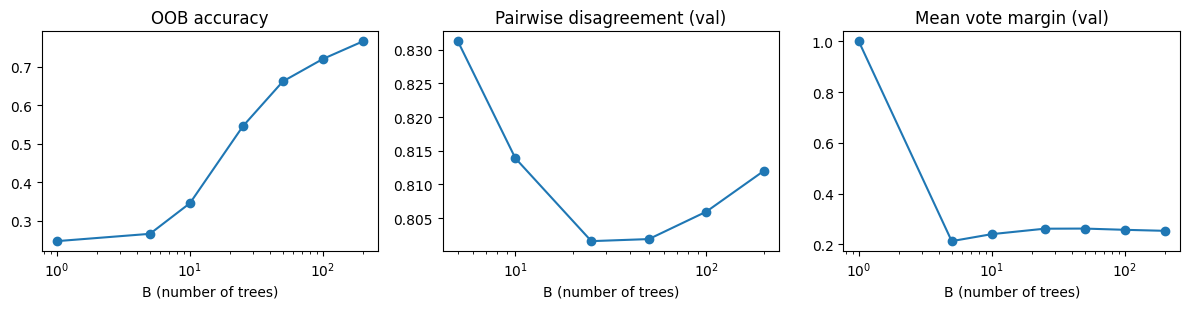

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
ax[0].plot(dfc.B, dfc.oob_acc, "o-"); ax[0].set_title("OOB accuracy")
ax[1].plot(dfc.B, dfc.disagreement, "o-"); ax[1].set_title("Pairwise disagreement (val)")
ax[2].plot(dfc.B, dfc.margin, "o-"); ax[2].set_title("Mean vote margin (val)")
for a in ax:
    a.set_xscale("log"); a.set_xlabel("B (number of trees)")
plt.tight_layout(); plt.savefig("q1c_plots.png", dpi=200); plt.show()

In [ ]:
B_FINAL = 100
tree0 = DecisionTreeClassifier(max_depth=frozen["depth"],
                               min_samples_leaf=frozen["min_samples_leaf"],
                               random_state=0).fit(Xtr, ytr)

def tree_out(Xs):
    pr = tree0.predict_proba(Xs)
    return pr.argmax(1), pr.max(1)          # confidence = leaf purity

def bag_out(Xs, B=B_FINAL):
    preds = np.array([t.predict(Xs) for t in trees[:B]])
    V = vote_matrix(preds, B)
    return V.argmax(1), V.max(1) / B, V     # confidence = winning vote fraction

rows = []
for name, Xs in [("clean", Xte), ("masked", Xte_m)]:
    tp, tc = tree_out(Xs)
    bp, bc, _ = bag_out(Xs)
    rows.append(dict(test_set=name,
                     tree_acc=(tp == yte).mean(), tree_conf=tc.mean(),
                     bag_acc=(bp == yte).mean(), bag_conf=bc.mean()))
dfd = pd.DataFrame(rows)
print(dfd.round(3).to_string())
dfd.to_csv("q1d_results.csv", index=False)

  test_set  tree_acc  tree_conf  bag_acc  bag_conf
0    clean     0.575      0.968    0.862     0.390
1   masked     0.175      1.000    0.838     0.297


bagging corrects tree: 25 | both wrong: 9
test idx 0: true=0, tree=39 (conf 1.00), bag=0, top votes=[(0, 35), (17, 9), (3, 9)], votes for true class=35
test idx 1: true=0, tree=4 (conf 0.83), bag=0, top votes=[(0, 26), (25, 12), (37, 8)], votes for true class=26
test idx 4: true=2, tree=3 (conf 0.86), bag=28, top votes=[(28, 16), (2, 11), (37, 9)], votes for true class=11
test idx 7: true=3, tree=35 (conf 1.00), bag=4, top votes=[(4, 13), (1, 9), (3, 8)], votes for true class=8


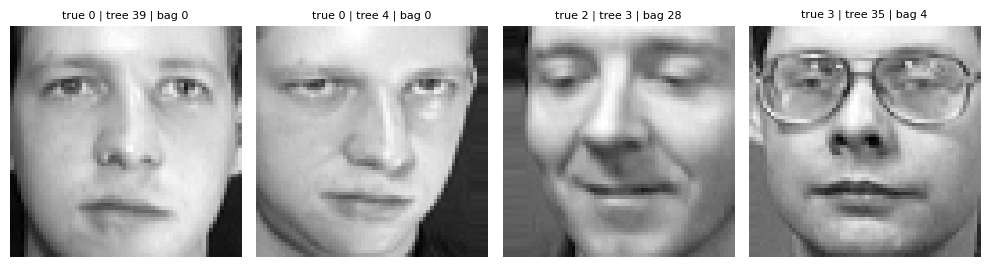

In [ ]:
tp, tc = tree_out(Xte)
bp, bc, Vb = bag_out(Xte)

fixed = np.where((tp != yte) & (bp == yte))[0]
both_wrong = np.where((tp != yte) & (bp != yte))[0]
print("bagging corrects tree:", len(fixed), "| both wrong:", len(both_wrong))

chosen = list(fixed[:2]) + list(both_wrong[:2])
for i in chosen:
    top3 = np.argsort(Vb[i])[::-1][:3]
    print(f"test idx {i}: true={yte[i]}, tree={tp[i]} (conf {tc[i]:.2f}), "
          f"bag={bp[i]}, top votes={[(int(c), int(Vb[i][c])) for c in top3]}, "
          f"votes for true class={int(Vb[i][yte[i]])}")

fig, ax = plt.subplots(1, 4, figsize=(10, 3))
for a, i in zip(ax, chosen):
    a.imshow(Xte[i].reshape(64, 64), cmap="gray"); a.axis("off")
    a.set_title(f"true {yte[i]} | tree {tp[i]} | bag {bp[i]}", fontsize=8)
plt.tight_layout(); plt.savefig("q1d_faces.png", dpi=200); plt.show()

In [ ]:
def in_block(f):
    r, c = divmod(f, 64)
    return 24 <= r <= 39 and 24 <= c <= 39

def frac_in_block(t):
    feats = t.tree_.feature[t.tree_.feature >= 0]
    return np.mean([in_block(f) for f in feats])

print("single tree:", frac_in_block(tree0))
print("bagged trees (mean):", np.mean([frac_in_block(t) for t in trees[:100]]))

single tree: 0.05
bagged trees (mean): 0.0599063952241401
